# Resistividad aparente y factores topográficos

**Nivel 2 — Análisis aplicado**  
**Prerrequisitos:** nivel 1 y arreglos/logaritmos; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

La fuente Slagdump está documentada, pero falta el archivo ERT crudo; conteos upstream son solo metadatos.

## Método

ERT estima resistividad a partir de potencial resolviendo una ecuación de conductividad discretizada. Un objetivo regularizado es `Φ(m)=||W_d(d−F(m))||²₂+λ||W_m(m−mref)||²₂`, a menudo con `m=logρ`; pesos codifican incertidumbre y suavidad espacial, λ intercambia ajuste y regularidad. Factores geométricos numéricos con topografía no equivalen a factores analíticos de terreno plano. El ejemplo upstream documenta 38 electrodos y 222 mediciones, metadatos publicados y no arreglos cargados aquí. Se comparan controles de malla por defecto y alternativos (`paraDX`, tamaño máximo en m) desde el código; la razón es sensibilidad de configuración, no convergencia ni resolución recuperada. Declare qué evidencia falta antes de interpretar una sección.

El factor geométrico convierte resistencia bajo hipótesis de semiespacio; no es resistividad verdadera a cierta profundidad. Muchas celdas afectan cada dato, con sensibilidad extensa y resolución dependiente de profundidad. Log protege positividad pero cambia el significado de suavidad. El refinamiento se juzga por predicciones estables con ajuste comparable, no por tamaño de celda solo.

## Resultados

Lea ejes físicos y unidades; distinga ajuste, error contra verdad sintética y acuerdo con etiquetas humanas. El recálculo debe concordar con el recibo. Un modelo graficado no demuestra unicidad, transferencia a campo ni resolución.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Verify source ledger and local presence of raw ERT inputs.
import json
from pathlib import Path
ledger=json.loads((root/"data/source-ledger.json").read_text(encoding="utf-8")); print("ledger mentions Slagdump:","slagdump" in json.dumps(ledger).lower()); raw=list((root/"data").rglob("*.ohm")); print("local .ohm files:",raw,"; inversion from field arrays possible:",bool(raw))

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
ledger mentions Slagdump: True
local .ohm files: [] ; inversion from field arrays possible: False


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

paraDX [0.3, 0.45] dimensionless; maximum cell size [10.0, 15.0] m; alternate/default ratios 1.5 1.5


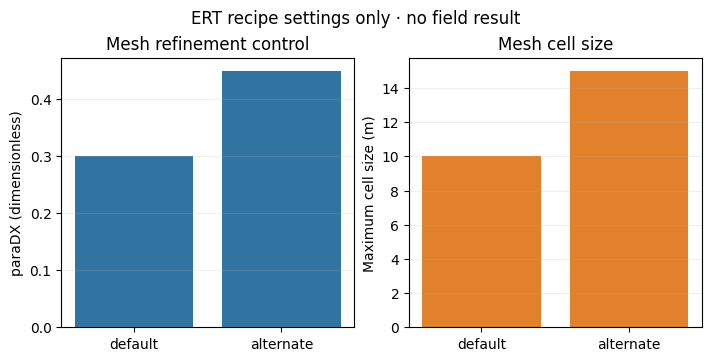

In [2]:
# Read default and alternate mesh parameters from the source AST; no mesh or field model is generated.
import ast
import numpy as np
import matplotlib.pyplot as plt
tree=ast.parse((root/"data-pipeline/ert.py").read_text(encoding="utf-8")); assigns={n.targets[0].id:n.value for n in tree.body if isinstance(n,ast.Assign) and isinstance(n.targets[0],ast.Name)}
default=ast.literal_eval(assigns["INVERSE_OPTIONS"]); alt_node=assigns["ALTERNATE_MESH_OPTIONS"]; overrides={k:ast.literal_eval(v) for k,v in zip([k.value for k in alt_node.keys if k is not None],[v for v in alt_node.values if not isinstance(v,ast.Name)])}; alternate={**default,**overrides}
labels=["default","alternate"]; dx=[default["paraDX"],alternate["paraDX"]]; cell=[default["paraMaxCellSize"],alternate["paraMaxCellSize"]]; print("paraDX",dx,"dimensionless; maximum cell size",cell,"m; alternate/default ratios",cell[1]/cell[0],dx[1]/dx[0])
fig,ax=plt.subplots(1,2,figsize=(7,3.5),constrained_layout=True); x=np.arange(2); ax[0].bar(x,dx,color="#3274a1"); ax[0].set(xticks=x,xticklabels=labels,ylabel="paraDX (dimensionless)",title="Mesh refinement control"); ax[1].bar(x,cell,color="#e1812c"); ax[1].set(xticks=x,xticklabels=labels,ylabel="Maximum cell size (m)",title="Mesh cell size"); [a.grid(axis="y",alpha=.2) for a in ax]; fig.suptitle("ERT recipe settings only · no field result"); plt.show()

### Experimento controlado de QC y geometría

Construye en memoria un sondeo Wenner `.ohm` **sintético** con elevaciones conocidas, respuesta nominal de semiespacio plano, dispersión con semilla fija y un valor atípico. Ejecuta el parser del repositorio, QC que solo marca, factores geométricos y validación predefinida. El factor ignora deliberadamente la elevación: compara la resistividad aparente diagnóstica con el relieve y explica por qué esto **no** es corrección topográfica ni inversión. No se infieren datos de terreno ni geología.

Las entradas y salidas son sintéticas; la marca conserva la medición y el factor plano es solo diagnóstico.

synthetic: 16 electrodes; 30 quadrupoles; relief=0.639 m
flagged zero-based rows=[5]; injected=5; all 30 measurements retained
predeclared split train=25 held=5; median apparent rho=99.07 ohm m; nominal rho=100 ohm m


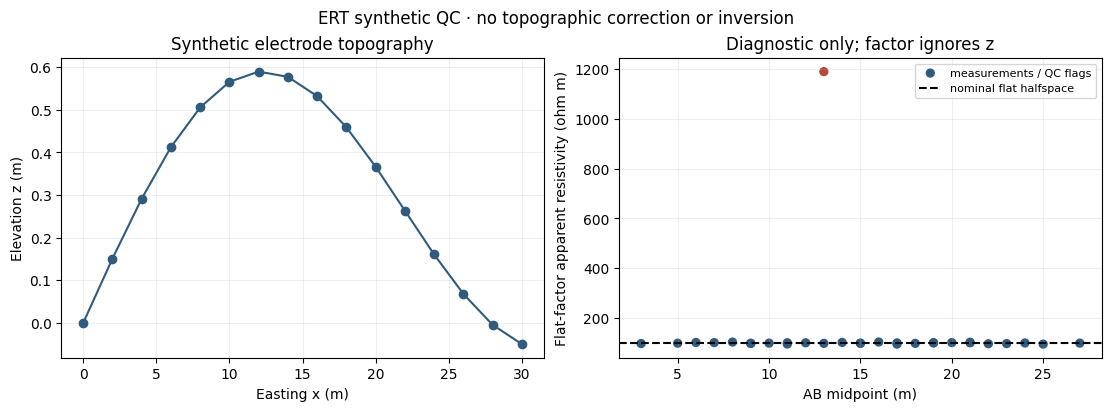

In [3]:
# Execute the documented experiment with the repository evidence.
import sys
sys.path.insert(0,str(root/"data-pipeline"))
import ert, numpy as np, matplotlib.pyplot as plt
ne=16; x=np.arange(ne,dtype=float)*2.; z=.45*np.sin(x/7.)+.012*x; rows=[]
for d in (1,2,3):
 for a in range(ne-3*d): rows.append((a+1,a+1+3*d,a+1+d,a+1+2*d))
def source(res):
 lines=["# Synthetic teaching fixture; not field data","# A Wenner array with 2m was applied.",f"{ne}# Number of sensors","#x z"]+[f"{xx:.6f} {zz:.6f}" for xx,zz in zip(x,z)]+[f"{len(rows)}# Number of data","#a b m n R"]+[f"{a} {b} {m} {n} {v:.12g}" for (a,b,m,n),v in zip(rows,res)]
 return ("\n".join(lines)+"\n").encode()
base=ert.parse_ohm_bytes(source(np.ones(len(rows)))); k=ert.flat_halfspace_factors(base); rng=np.random.default_rng(20261027); r=100./k*np.exp(rng.normal(0,.025,len(rows))); outlier=min(5,len(r)-1); r[outlier]*=12
s=ert.parse_ohm_bytes(source(r)); report=ert.qc(s); train,held=ert.holdout_indices(s); app=ert.flat_halfspace_factors(s)*s.resistance_ohm
print(f"synthetic: {report['sensor_count']} electrodes; {report['measurement_count']} quadrupoles; relief={report['topographic_relief_m']:.3f} m")
print(f"flagged zero-based rows={report['flagged_rows']}; injected={outlier}; all {len(r)} measurements retained")
print(f"predeclared split train={len(train)} held={len(held)}; median apparent rho={np.median(app):.2f} ohm m; nominal rho=100 ohm m")
fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True); ax[0].plot(x,z,"o-",color="#315b7d"); ax[0].set(xlabel="Easting x (m)",ylabel="Elevation z (m)",title="Synthetic electrode topography"); ax[0].grid(alpha=.2)
mid=(x[s.abmn[:,0]]+x[s.abmn[:,1]])/2; flagged=np.isin(np.arange(len(app)),report["flagged_rows"]); ax[1].scatter(mid,app,c=np.where(flagged,"#b34a36","#315b7d"),s=32,label="measurements / QC flags"); ax[1].axhline(100,color="black",ls="--",label="nominal flat halfspace"); ax[1].set(xlabel="AB midpoint (m)",ylabel="Flat-factor apparent resistivity (ohm m)",title="Diagnostic only; factor ignores z"); ax[1].grid(alpha=.2); ax[1].legend(fontsize=8); fig.suptitle("ERT synthetic QC · no topographic correction or inversion"); plt.show()

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)